In [1]:
#Bank Marketing: Which customer characteristics and campaign-related factors are associated with the success of a bank marketing campaign?

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import binom, poisson, norm

In [3]:
df=pd.read_csv('bank-full.csv', sep=';')  #using sep=';' because panda wasn't reconizing the separator used in my csv file.
print(f"Total: {len(df)}")

Total: 45211


In [4]:
with open("bank-full.csv", "r", encoding="utf-8") as arquivo:
    total_entradas = sum(1 for linha in arquivo)

print(f"O arquivo tem {total_entradas} entradas.")

O arquivo tem 45212 entradas.


In [5]:
df.head(10)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


In [6]:
df.tail(10)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45201,53,management,married,tertiary,no,583,no,no,cellular,17,nov,226,1,184,4,success,yes
45202,34,admin.,single,secondary,no,557,no,no,cellular,17,nov,224,1,-1,0,unknown,yes
45203,23,student,single,tertiary,no,113,no,no,cellular,17,nov,266,1,-1,0,unknown,yes
45204,73,retired,married,secondary,no,2850,no,no,cellular,17,nov,300,1,40,8,failure,yes
45205,25,technician,single,secondary,no,505,no,yes,cellular,17,nov,386,2,-1,0,unknown,yes
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


In [7]:
df.shape

(45211, 17)

In [8]:
#Non-null: Not missing values
#int64: Integer (Whole number)
#Object: Text or categorical data.

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [9]:
df.dtypes

age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object

In [10]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [11]:
print("Column names:")
df.columns.tolist()


Column names:


['age',
 'job',
 'marital',
 'education',
 'default',
 'balance',
 'housing',
 'loan',
 'contact',
 'day',
 'month',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'poutcome',
 'y']

In [12]:
categorical_vars = df.select_dtypes(include="object").columns.tolist()
numerical_vars = df.select_dtypes(include="number").columns.tolist()

categorical_vars = df.select_dtypes(include="object").columns.tolist()
numerical_vars = df.select_dtypes(include="number").columns.tolist()

print("Categorical variables:")
print(categorical_vars)

print("\nNumerical variables:")
print(numerical_vars)


Categorical variables:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']

Numerical variables:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


In [13]:
selected_vars = ["age", "balance", "duration", "campaign", "previous"]
print(df[selected_vars].describe().round(2))


            age    balance  duration  campaign  previous
count  45211.00   45211.00  45211.00  45211.00  45211.00
mean      40.94    1362.27    258.16      2.76      0.58
std       10.62    3044.77    257.53      3.10      2.30
min       18.00   -8019.00      0.00      1.00      0.00
25%       33.00      72.00    103.00      1.00      0.00
50%       39.00     448.00    180.00      2.00      0.00
75%       48.00    1428.00    319.00      3.00      0.00
max       95.00  102127.00   4918.00     63.00    275.00


In [14]:

summary = df[selected_vars].describe().T #.T: transposes the table so that each variable appears in a row.

summary["median"] = df[selected_vars].median()
summary["variance"] = df[selected_vars].var()
summary["skewness"] = df[selected_vars].skew() #Checando assimetria (checking for asymmetry)

print(summary.round(2))

            count     mean      std     min    25%    50%     75%       max  \
age       45211.0    40.94    10.62    18.0   33.0   39.0    48.0      95.0   
balance   45211.0  1362.27  3044.77 -8019.0   72.0  448.0  1428.0  102127.0   
duration  45211.0   258.16   257.53     0.0  103.0  180.0   319.0    4918.0   
campaign  45211.0     2.76     3.10     1.0    1.0    2.0     3.0      63.0   
previous  45211.0     0.58     2.30     0.0    0.0    0.0     0.0     275.0   

          median    variance  skewness  
age         39.0      112.76      0.68  
balance    448.0  9270598.95      8.36  
duration   180.0    66320.57      3.14  
campaign     2.0        9.60      4.90  
previous     0.0        5.31     41.85  


In [15]:
#Checking Unknown values

for col in categorical_vars:
    unknown_count = (df[col] == "unknown").sum()
    print(f"{col}: {unknown_count}")

job: 288
marital: 0
education: 1857
default: 0
housing: 0
loan: 0
contact: 13020
month: 0
poutcome: 36959
y: 0


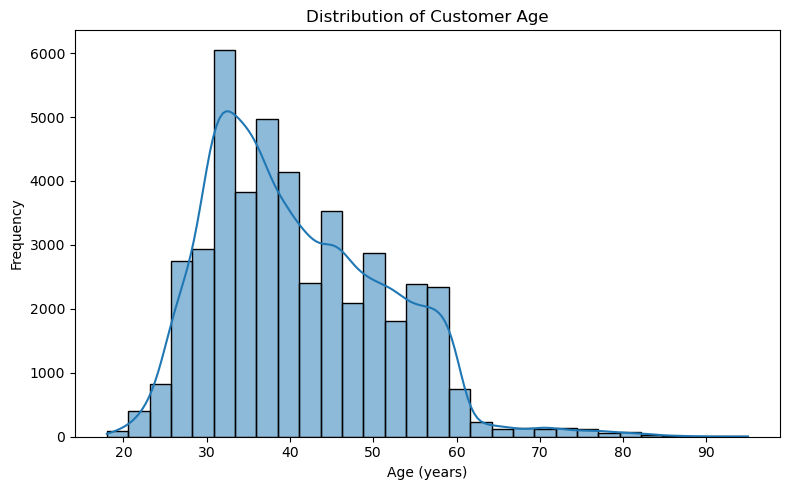

In [16]:
#Creating histogram

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="age", bins=30, kde=True)

plt.title("Distribution of Customer Age")
plt.xlabel("Age (years)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


In [17]:
df["success"] = (df["y"] == "yes").astype(int)
print(df[["job", "y", "success"]].head(10))


            job   y  success
0    management  no        0
1    technician  no        0
2  entrepreneur  no        0
3   blue-collar  no        0
4       unknown  no        0
5    management  no        0
6    management  no        0
7  entrepreneur  no        0
8       retired  no        0
9    technician  no        0


In [18]:
success_by_job = (df.groupby("job")["success"].mean().sort_values(ascending=False) * 100)
print(success_by_job.round(2))


job
student          28.68
retired          22.79
unemployed       15.50
management       13.76
admin.           12.20
self-employed    11.84
unknown          11.81
technician       11.06
services          8.88
housemaid         8.79
entrepreneur      8.27
blue-collar       7.27
Name: success, dtype: float64


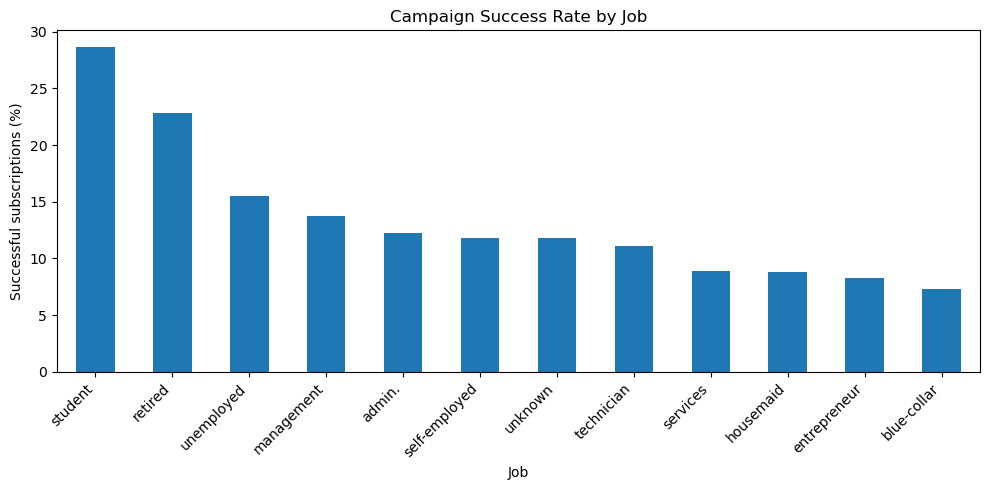

In [19]:
plt.figure(figsize=(10, 5))

success_by_job.plot(kind="bar")

plt.title("Campaign Success Rate by Job")
plt.xlabel("Job")
plt.ylabel("Successful subscriptions (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [28]:
balance_by_outcome = df.groupby("y")["balance"].agg(["count", "mean", "median", "std", "min", "max"])
print(balance_by_outcome.round(2))

     count     mean  median     std   min     max
y                                                
no   39922  1303.71   417.0  2974.2 -8019  102127
yes   5289  1804.27   733.0  3501.1 -3058   81204


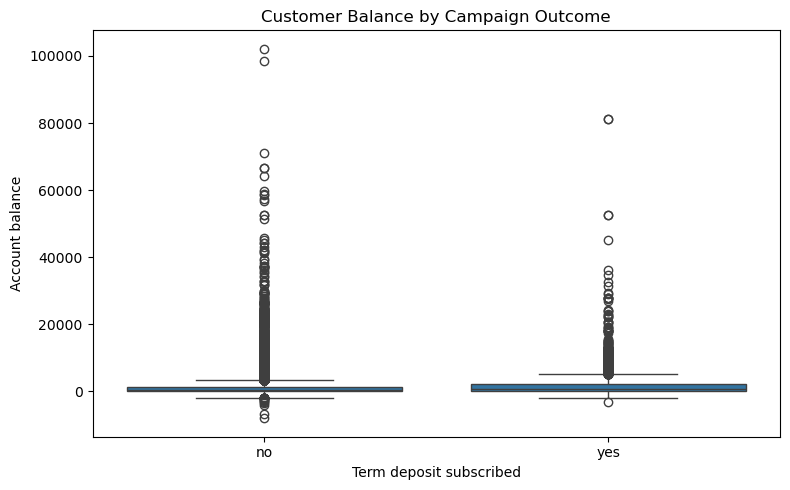

In [29]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="y", y="balance", showfliers=True)

plt.title("Customer Balance by Campaign Outcome")
plt.xlabel("Term deposit subscribed")
plt.ylabel("Account balance")

plt.tight_layout()
plt.show()

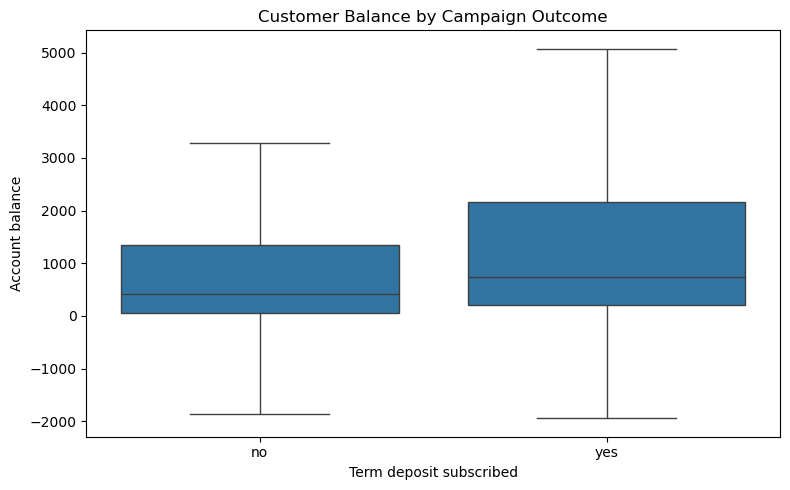

In [46]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="y", y="balance", showfliers=False)

plt.title("Customer Balance by Campaign Outcome")
plt.xlabel("Term deposit subscribed")
plt.ylabel("Account balance")

plt.tight_layout()
plt.show()

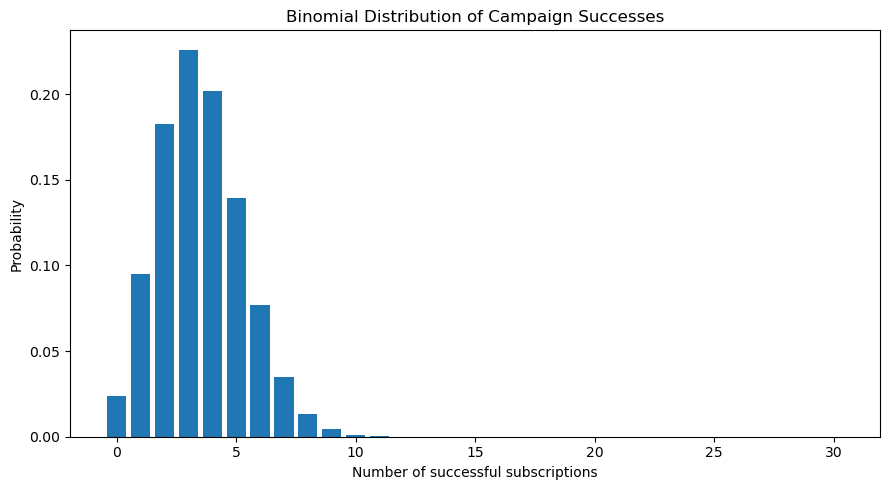

In [47]:
n = 30
p = df["success"].mean()
x = np.arange(0, n + 1)
probabilities = binom.pmf(x, n, p)

plt.figure(figsize=(9, 5))
plt.bar(x, probabilities)

plt.title("Binomial Distribution of Campaign Successes")
plt.xlabel("Number of successful subscriptions")
plt.ylabel("Probability")

plt.tight_layout()
plt.show()

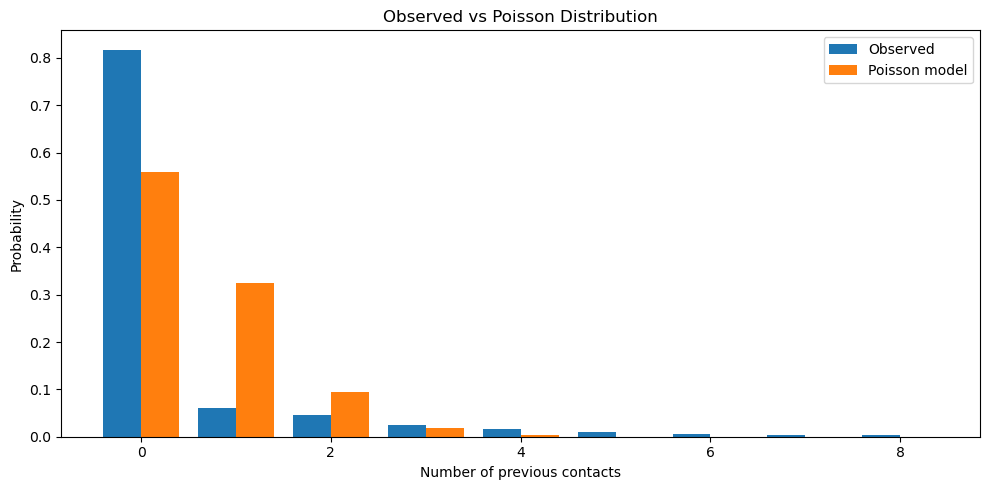

In [48]:
lam = df["previous"].mean()
max_k = int(df["previous"].quantile(0.99))
x = np.arange(0, max_k + 1)

observed = (df["previous"].value_counts(normalize=True).reindex(x, fill_value=0))
expected = poisson.pmf(x, mu=lam)

plt.figure(figsize=(10, 5))
plt.bar(x - 0.2, observed, width=0.4, label="Observed")
plt.bar(x + 0.2, expected, width=0.4, label="Poisson model")

plt.title("Observed vs Poisson Distribution")
plt.xlabel("Number of previous contacts")
plt.ylabel("Probability")
plt.legend()
plt.tight_layout()
plt.show()

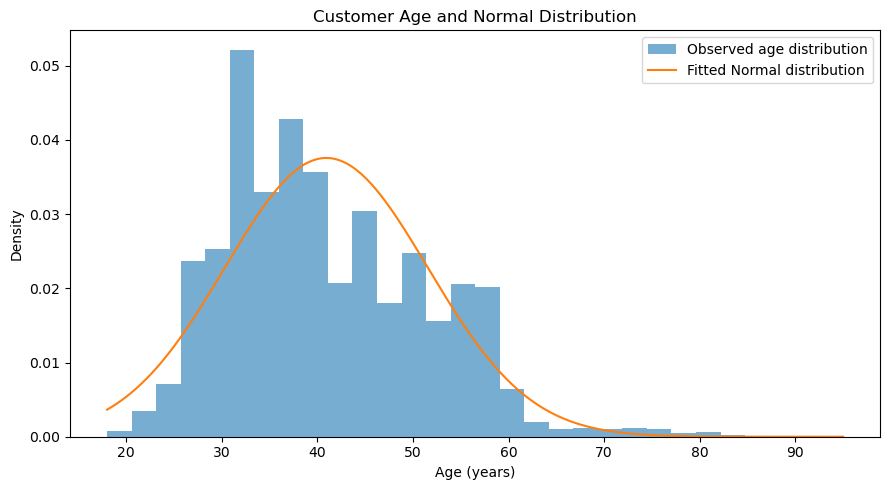

In [53]:
plt.figure(figsize=(9, 5))
plt.hist(age, bins=30, density=True, alpha=0.6,
         label="Observed age distribution")
plt.plot(x, norm.pdf(x, loc=mu, scale=sigma),
         label="Fitted Normal distribution")

plt.title("Customer Age and Normal Distribution")
plt.xlabel("Age (years)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

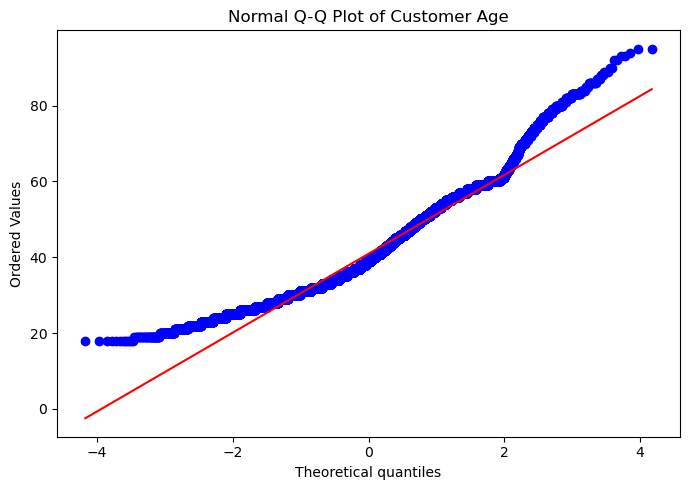

In [54]:
plt.figure(figsize=(7, 5))

stats.probplot(age, dist="norm", plot=plt)

plt.title("Normal Q-Q Plot of Customer Age")
plt.tight_layout()
plt.show()